# 08. Desbalance de clases y entrenamiento disciplinado

Compararemos **pérdida ponderada** y **focal loss** en las tres arquitecturas del paso 07. Ambas tareas se entrenan juntas: 0.60 para binaria y 0.40 para multiclase. Usamos todos los ejemplos de entrenamiento con historia suficiente para 168 horas, las mismas horas de validación y ninguna observación de prueba.

El notebook ejecuta el entrenamiento completo, restaura la mejor época por PR-AUC de validación y muestra sus resultados y curvas aquí. No guarda figuras, métricas ni modelos en archivos separados. La implementación reutilizable está en `entrenamiento_secuencial.py`.

Esta es una búsqueda con presupuesto limitado y explícito; no una garantía de convergencia ni una evaluación final independiente. La comparación detallada con la línea base y la anticipación por eventos se hará en el siguiente paso.

Este notebook reúne dos apartados que comparten los mismos entrenamientos:

- **2.3. Desbalance de clases:** comparamos pérdida ponderada y focal, y revisamos su efecto en la calibración. Se desarrolla en las secciones 2, 5 y 7.
- **2.4. Entrenamiento disciplinado:** declaramos las reglas y el presupuesto antes de entrenar, usamos early stopping y regularización, y revisamos las curvas de aprendizaje. Se desarrolla en las secciones 3, 4, 5 y 6.

No son dos entrenamientos independientes: las mismas reglas se aplican a ambas pérdidas para que la comparación sea justa. Las secciones siguientes explican por separado qué se evalúa y cómo se entrenó.


## 1. Recuperar la preparación y el entrenamiento compartidos

El módulo del paso 06 reconstruye las ventanas en memoria. No necesitamos ejecutar antes otros notebooks ni modificar los CSV.

### ¿Para qué sirve el archivo `.py`?

`entrenamiento_secuencial.py` contiene las funciones para calcular las pérdidas, entrenar, conservar la mejor época y obtener las métricas. **El notebook importa esas funciones y las llama desde sus celdas.** Aquí se explica el procedimiento y se muestran las tablas y gráficas.

**El `.py` no sustituye al notebook; se complementan.** Para repetir el análisis ejecutamos el notebook, manteniendo el `.py` en esta misma carpeta y los módulos de los pasos 06 y 07 en sus ubicaciones. No hay que ejecutar el `.py` por separado. Separar las funciones permite reutilizarlas sin copiar todo el código.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

# Encontrar los módulos y los archivos sin imprimir rutas de la computadora.
actual = Path.cwd()
if (actual / "Datos").is_dir():
    ruta_repo = actual
elif (actual.parent / "Datos").is_dir():
    ruta_repo = actual.parent
else:
    raise FileNotFoundError("No se encontró la carpeta Datos.")
for carpeta in ["Preprocesamiento", "Modelación"]:
    ruta = str(ruta_repo / carpeta)
    if ruta not in sys.path:
        sys.path.insert(0, ruta)

from preparar_secuencias import preparar_secuencias
from entrenamiento_secuencial import (
    ejecutar_comparacion, indices_comunes, calcular_pesos, PerdidaDesbalanceada,
)

preparacion = preparar_secuencias(ruta_repo)
indices = indices_comunes(preparacion)
comunes = preparacion["anclas"][168]["entrenamiento"]
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_rows", 30)
print("Anclas comunes de entrenamiento:", len(comunes))
print("Horas de validación:", len(preparacion["datasets"][24]["validación"]))

Anclas comunes de entrenamiento: 563500
Horas de validación: 144000


Se usan **563,500 horas de entrenamiento**, sin submuestrear clases, y las mismas **144,000 de validación**. La restricción de historia de 168 horas se aplica a todos los ensayos para que al cambiar la longitud no cambien los ejemplos. No es una nueva partición: se conservan las mismas fechas y etiquetas; se excluyen únicamente las anclas iniciales sin historia común suficiente.

Esto difiere ligeramente de las 580,200 horas usadas por la línea base y deberá indicarse al compararlas. No se elimina ninguna fila de los CSV. Validación conserva su prevalencia natural.

## 2. Desbalance de clases: estrategias y pesos (2.3)

**Pérdida ponderada:** aumenta la contribución de las clases poco frecuentes. Para una clase con `n_c` ejemplos usamos `N / (K × n_c)`, donde `K` es 2 para binaria y 5 para multiclase. El promedio de esos pesos en entrenamiento es 1.

**Focal loss:** usa los mismos pesos y añade el factor `(1 − p_t)^2`, donde `p_t` es la probabilidad de la respuesta correcta. Si un ejemplo ya está bien resuelto, su contribución se reduce; los ejemplos difíciles mantienen más influencia. Usar los mismos pesos permite estudiar el efecto adicional del factor focal, sin cambiar también el balance de clases.

Se aplica a la tarea binaria y a la multiclase, conservando la combinación **0.60 × binaria + 0.40 × multiclase**. En el caso ponderado, focal con gamma 0 equivale a la entropía cruzada ponderada usada aquí. Los pesos se calculan únicamente sobre las anclas comunes de entrenamiento.

No usamos submuestreo de horas sanas ni sobremuestreo de ventanas previas a falla: ya se comparan dos estrategias y queremos conservar los mismos datos. La focal se basa en [Lin et al., Focal Loss for Dense Object Detection (2017)](https://arxiv.org/abs/1708.02002), adaptada aquí a las dos tareas de clasificación.

In [2]:
# Revisar los pesos aprendidos de las clases de entrenamiento, sin mirar las de validación.
pesos_binarios, pesos_multi = calcular_pesos(comunes)
conteo_bin = np.bincount(comunes["etiqueta_binaria"].to_numpy(dtype=int), minlength=2)
conteo_multi = np.bincount(comunes["clase_codigo"].to_numpy(dtype=int), minlength=5)
display(pd.DataFrame({"clase_binaria": [0, 1], "horas": conteo_bin, "peso": pesos_binarios}))
display(pd.DataFrame({"clase": ["ninguno", "comp1", "comp2", "comp3", "comp4"], "horas": conteo_multi, "peso": pesos_multi}))
assert np.isclose((conteo_bin * pesos_binarios).sum() / len(comunes), 1)
assert np.isclose((conteo_multi * pesos_multi).sum() / len(comunes), 1)

,clase_binaria,horas,peso
0,0,552477,0.509976
1,1,11023,25.560192


,clase,horas,peso
0,ninguno,552477,0.203990
1,comp1,3072,36.686198
2,comp2,3643,30.936042
3,comp3,1932,58.333333
4,comp4,2376,47.432660


Los pesos modifican el error usado para aprender, **no las etiquetas ni las probabilidades reales de falla**. Una clase rara puede recibir un peso grande; por eso limitamos la norma del gradiente a 1.0 para evitar actualizaciones inestables.

## 3. Entrenamiento disciplinado: reglas y presupuesto (2.4)

### 3.1. Qué buscamos y cuántos ensayos permitimos

La búsqueda se definió con **ocho ensayos como máximo**. Un ensayo significa entrenar desde cero una combinación:

1. Seis ensayos con ventanas de 24 horas: LSTM, TCN y CNN-LSTM, cada una con pérdida ponderada y focal.
2. La combinación de arquitectura y pérdida con mayor PR-AUC de validación se prueba además con ventanas de 72 y 168 horas.

Es una **búsqueda manual y por etapas** sobre arquitectura, estrategia de pérdida y longitud de ventana. No usamos Optuna. Los 30 ensayos son un ejemplo de presupuesto, no una cantidad obligatoria. Aquí declaramos ocho para limitar el costo y poder comparar las dos estrategias en las tres arquitecturas.

La tasa de aprendizaje, el tamaño de las capas, dropout y los demás parámetros se mantienen fijos. Por eso esta búsqueda es limitada: no demuestra que hayamos encontrado la mejor configuración posible. Tampoco explora las 18 combinaciones de tres arquitecturas, dos pérdidas y tres longitudes.

### 3.2. Early stopping: cuándo detener y qué época conservar

Cada ensayo tiene un máximo de **6 épocas**. Una época recorre una vez todas las ventanas de entrenamiento. Al terminarla, calculamos **PR-AUC de validación como average precision (AP)**; un valor mayor es mejor.

Usamos paciencia de **2 épocas** y una mejora de referencia de **0.0001**. Si una época no supera el mejor valor anterior en más de esa cantidad, aumenta el contador de espera. Una mejora suficiente reinicia el contador; dos épocas seguidas sin ella detienen el ensayo. Siempre conservamos y restauramos el estado con la mayor PR-AUC observada, aunque una mejora pequeña no reinicie la paciencia. No usamos la pérdida de entrenamiento para elegir la mejor época.

Early stopping puede ayudar a limitar entrenamiento innecesario, pero no obliga a terminar antes del máximo. Si el modelo sigue mejorando, puede ejecutar las seis épocas.

### 3.3. Regularización y parámetros fijos

- **Dropout de 0.10:** durante entrenamiento desactiva al azar parte de las activaciones en las capas donde se definió. Ayuda a que el modelo no dependa siempre de las mismas conexiones. Se desactiva al evaluar.
- **Weight decay de 0.0001:** AdamW reduce los pesos durante las actualizaciones, lo que limita que crezcan demasiado y ayuda a controlar el sobreajuste.
- **Recorte de gradiente a 1.0:** limita la magnitud de las actualizaciones cuando el gradiente es grande. Es una medida de estabilidad, diferente de dropout y weight decay.

Usamos AdamW con tasa de aprendizaje **0.001**, lotes de **512** y la pérdida combinada **0.60 × binaria + 0.40 × multiclase** del paso 07. Estos valores no se modifican entre las dos estrategias.

### 3.4. Reproducibilidad y uso de los conjuntos

La semilla **42** se reinicia en cada ensayo. Para una misma arquitectura se repiten la inicialización y el orden de lotes al comparar pérdidas. Los cálculos se configuran como deterministas en CPU. Se usa un hilo, elegido mediante una comprobación de tiempo sin etiquetas; la duración dependerá del equipo.

Las ventanas de entrenamiento se presentan en orden aleatorio, pero las horas dentro de cada ventana conservan su orden. Validación no se permuta ni remuestrea y mantiene su proporción natural de clases. Se utiliza para elegir época y configuración; **prueba no se utiliza**. Como tomamos decisiones con validación, sus resultados son de desarrollo y no una evaluación final independiente.


In [3]:
# Parámetros declarados antes de obtener los resultados de entrenamiento.
configuracion = {"semilla": 42, "hilos": 1, "batch_size": 512, "max_epocas": 6,
                 "paciencia": 2, "min_delta": 0.0001, "learning_rate": 0.001,
                 "weight_decay": 0.0001, "dropout": 0.10}
display(pd.DataFrame(list(configuracion.items()), columns=["parámetro", "valor"]))

,parámetro,valor
0,semilla,42.0000
1,hilos,1.0000
2,batch_size,512.0000
3,max_epocas,6.0000
4,paciencia,2.0000
5,min_delta,0.0001
6,learning_rate,0.0010
7,weight_decay,0.0001
8,dropout,0.1000


## 4. Ejecutar los ocho ensayos

Esta celda usa todos los lotes de las anclas comunes, sin una muestra reducida. Por cada época muestra progreso, PR-AUC y duración. El tiempo puede ser considerable en CPU.

Las pérdidas total, binaria y multiclase se registran por separado tanto en entrenamiento como en validación. **No deben compararse directamente las magnitudes de ponderada y focal**, porque son funciones distintas. La selección usa PR-AUC sobre la misma validación, no la menor pérdida numérica entre estrategias.

In [4]:
# Ejecutar el presupuesto completo y mantener modelos, historias y predicciones en memoria.
resultados = ejecutar_comparacion(preparacion, configuracion)
comparacion = pd.DataFrame([ensayo["resumen"] for ensayo in resultados.values()])
historial = pd.concat([ensayo["historial"] for ensayo in resultados.values()], ignore_index=True)
assert len(resultados) == 8
assert (comparacion["filas_entrenamiento"] == len(comunes)).all()
assert (comparacion["filas_validacion"] == 144000).all()
display(comparacion.round(5))

INICIO LSTM | L=24 | ponderada
LSTM | L=24 | ponderada época 1 lotes 300 / 1101
LSTM | L=24 | ponderada época 1 lotes 600 / 1101
LSTM | L=24 | ponderada época 1 lotes 900 / 1101
LSTM | L=24 | ponderada FIN época 1 PR-AUC 0.571725 segundos 32.2
LSTM | L=24 | ponderada época 2 lotes 300 / 1101
LSTM | L=24 | ponderada época 2 lotes 600 / 1101
LSTM | L=24 | ponderada época 2 lotes 900 / 1101
LSTM | L=24 | ponderada FIN época 2 PR-AUC 0.920233 segundos 32.5
LSTM | L=24 | ponderada época 3 lotes 300 / 1101
LSTM | L=24 | ponderada época 3 lotes 600 / 1101
LSTM | L=24 | ponderada época 3 lotes 900 / 1101
LSTM | L=24 | ponderada FIN época 3 PR-AUC 0.982673 segundos 30.9
LSTM | L=24 | ponderada época 4 lotes 300 / 1101
LSTM | L=24 | ponderada época 4 lotes 600 / 1101
LSTM | L=24 | ponderada época 4 lotes 900 / 1101
LSTM | L=24 | ponderada FIN época 4 PR-AUC 0.983172 segundos 31.9
LSTM | L=24 | ponderada época 5 lotes 300 / 1101
LSTM | L=24 | ponderada época 5 lotes 600 / 1101
LSTM | L=24 | ponde

,arquitectura,L,estrategia,epocas_ejecutadas,mejor_epoca,filas_entrenamiento,filas_validacion,segundos_totales,PR_AUC_AP,ROC_AUC,Brier,log_loss,ECE_10_bins,F1_macro_5_clases
0,LSTM,24,ponderada,6,6,563500,144000,197.71985,0.98570,0.99956,0.00089,0.00577,0.00084,0.97063
1,LSTM,24,focal,6,6,563500,144000,195.85753,0.99439,0.99984,0.00098,0.00830,0.00610,0.95415
2,TCN,24,ponderada,6,6,563500,144000,1025.23613,0.99619,0.99993,0.00088,0.00413,0.00087,0.97624
3,TCN,24,focal,6,6,563500,144000,997.23704,0.99081,0.99983,0.00962,0.03645,0.02641,0.72353
4,CNN-LSTM,24,ponderada,6,6,563500,144000,289.28417,0.99751,0.99996,0.00073,0.00373,0.00080,0.97551
5,CNN-LSTM,24,focal,6,6,563500,144000,291.23118,0.99281,0.99973,0.00129,0.00991,0.00743,0.96237
6,CNN-LSTM,72,ponderada,6,6,563500,144000,664.18288,0.97887,0.99965,0.00366,0.01632,0.00431,0.89702
7,CNN-LSTM,168,ponderada,6,6,563500,144000,1434.48289,0.97822,0.99970,0.00276,0.01313,0.00321,0.92255


Se completaron los **ocho ensayos** con todas las **563,500 anclas comunes de entrenamiento** y las **144,000 horas de validación**, sin submuestreo ni sobremuestreo. En total se ejecutaron **48 épocas** entre todos los ensayos; cada modelo se restauró a su mejor época por PR-AUC.

La comparación conserva los mismos datos, pesos de clase y parámetros de ajuste. Los cambios de estrategia no alteran las etiquetas ni las ventanas. Las duraciones de la tabla corresponden a esta CPU y no son una propiedad fija de la arquitectura.

**Early stopping no significa necesariamente detenerse antes del máximo:** si la mejora continúa, el ensayo llega al límite de seis épocas. La tabla distingue cuántas ejecutó y cuál se conservó. Llegar al máximo tampoco demuestra que el modelo haya convergido.

En esta ejecución **ningún ensayo se detuvo antes del máximo**: todos completaron seis épocas y su mejor época fue la sexta. El mecanismo de early stopping estuvo activo, pero no se alcanzó su condición de parada. No se amplió el presupuesto después de ver los resultados.


## 5. Comparación de estrategias (2.3) y curvas de aprendizaje (2.4)

Comparamos los seis ensayos de 24 horas. PR-AUC se calcula como average precision (AP), igual que en la primera fase. La proporción positiva de validación sirve como referencia de un puntaje constante. F1 macro aquí promedia las cinco clases con la clase de mayor probabilidad.

La selección de épocas y ensayos usa validación, por lo que estas cifras son de desarrollo. No son resultados finales de prueba ni intervalos de confianza entre semillas.

### Cómo leer las curvas

El eje horizontal muestra las épocas. A la izquierda vemos PR-AUC de validación: buscamos que aumente. A la derecha vemos la pérdida combinada de entrenamiento y validación: dentro de una misma estrategia, valores menores indican mejor ajuste a su objetivo.

Si la pérdida de entrenamiento baja mientras la de validación sube de forma sostenida, puede haber sobreajuste. Las curvas se interpretan junto con PR-AUC, porque una pérdida menor no garantiza ordenar mejor las fallas. **No comparamos directamente el tamaño de la pérdida focal con el de la ponderada**, ya que sus fórmulas son distintas.


,arquitectura,estrategia,mejor_epoca,PR_AUC_AP,ROC_AUC,F1_macro_5_clases,Brier,ECE_10_bins
0,LSTM,ponderada,6,0.98570,0.99956,0.97063,0.00089,0.00084
1,LSTM,focal,6,0.99439,0.99984,0.95415,0.00098,0.00610
2,TCN,ponderada,6,0.99619,0.99993,0.97624,0.00088,0.00087
3,TCN,focal,6,0.99081,0.99983,0.72353,0.00962,0.02641
4,CNN-LSTM,ponderada,6,0.99751,0.99996,0.97551,0.00073,0.00080
5,CNN-LSTM,focal,6,0.99281,0.99973,0.96237,0.00129,0.00743


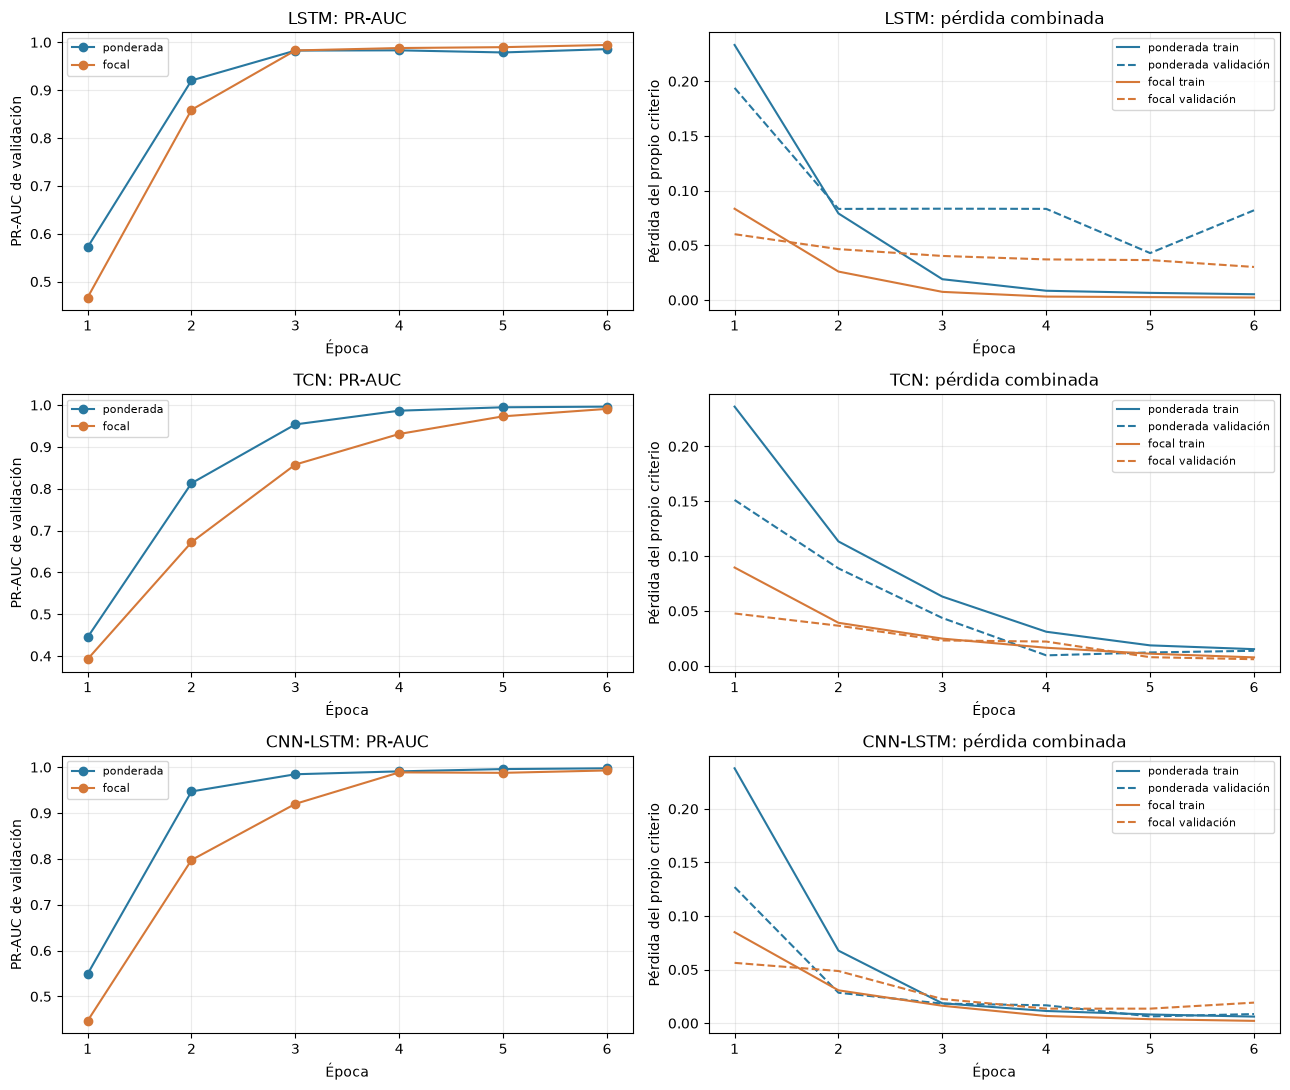

In [5]:
comparacion_24h = comparacion.loc[comparacion["L"] == 24].copy()
display(comparacion_24h[["arquitectura", "estrategia", "mejor_epoca", "PR_AUC_AP", "ROC_AUC", "F1_macro_5_clases", "Brier", "ECE_10_bins"]].round(5))

# Mostrar las curvas dentro del notebook, sin exportar imágenes.
fig, ejes = plt.subplots(3, 2, figsize=(13, 11))
for fila, arquitectura in enumerate(["LSTM", "TCN", "CNN-LSTM"]):
    for estrategia, color in [("ponderada", "#2878a0"), ("focal", "#d57838")]:
        h = resultados[(arquitectura, 24, estrategia)]["historial"]
        ejes[fila, 0].plot(h["epoca"], h["PR_AUC_validacion"], marker="o", label=estrategia, color=color)
        ejes[fila, 1].plot(h["epoca"], h["train_total"], label=estrategia + " train", color=color)
        ejes[fila, 1].plot(h["epoca"], h["val_total"], linestyle="--", label=estrategia + " validación", color=color)
    ejes[fila, 0].set(title=arquitectura + ": PR-AUC", xlabel="Época", ylabel="PR-AUC de validación")
    ejes[fila, 1].set(title=arquitectura + ": pérdida combinada", xlabel="Época", ylabel="Pérdida del propio criterio")
    for eje in ejes[fila]:
        eje.legend(fontsize=8)
        eje.grid(alpha=0.25)
fig.tight_layout()
plt.show()

- **LSTM:** PR-AUC de **0.9857** con ponderada y **0.9944** con focal.
- **TCN:** PR-AUC de **0.9962** con ponderada y **0.9908** con focal.
- **CNN-LSTM:** PR-AUC de **0.9975** con ponderada y **0.9928** con focal.

La mejor combinación de 24 horas fue **CNN-LSTM con pérdida ponderada**, con PR-AUC **0.9975**. Focal mejoró el resultado de LSTM en esta ejecución, pero no el de TCN ni CNN-LSTM: **no hay una estrategia universalmente mejor**.

Estas conclusiones corresponden a gamma 2, los pesos y el presupuesto declarados y una sola semilla. No prueban que focal sea inferior con otras configuraciones o más entrenamiento. La escala de sus pérdidas no es comparable directamente con la ponderada.

En LSTM con pérdida ponderada, la pérdida de validación aumenta al final mientras la de entrenamiento sigue bajando, aunque PR-AUC alcanza su mejor valor en la sexta época. Esto muestra que ambas medidas pueden comportarse de manera diferente. La época se conserva según la regla declarada de PR-AUC; las curvas ayudan a detectar límites del ajuste, pero no justifican cambiar esa regla después de ver el resultado.


### Pérdidas de las dos tareas por separado

La siguiente figura permite revisar si una tarea domina el valor de la pérdida combinada. Los coeficientes 0.60 y 0.40 no igualan automáticamente sus escalas ni sus gradientes.

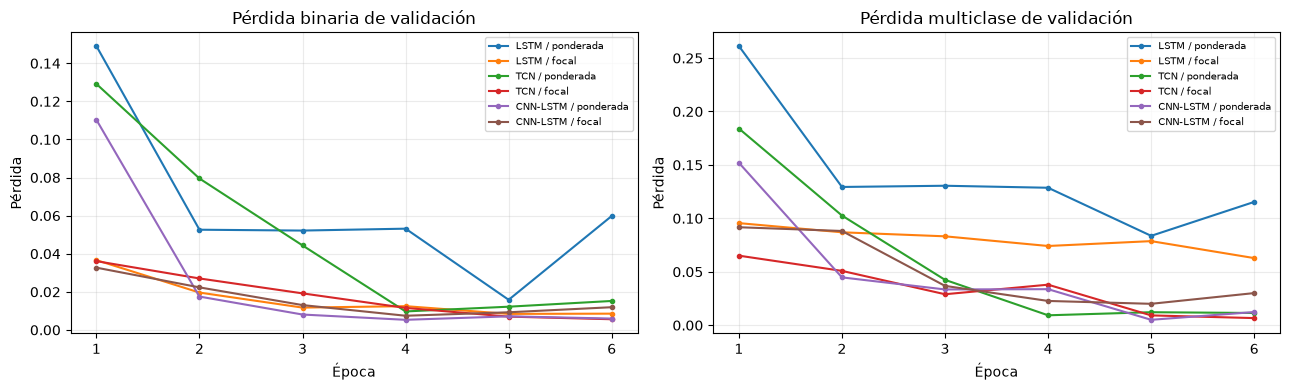

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for clave, ensayo in resultados.items():
    if clave[1] != 24:
        continue
    h = ensayo["historial"]
    etiqueta = clave[0] + " / " + clave[2]
    ejes[0].plot(h["epoca"], h["val_binaria"], marker=".", label=etiqueta)
    ejes[1].plot(h["epoca"], h["val_multiclase"], marker=".", label=etiqueta)
ejes[0].set(title="Pérdida binaria de validación", xlabel="Época", ylabel="Pérdida")
ejes[1].set(title="Pérdida multiclase de validación", xlabel="Época", ylabel="Pérdida")
for eje in ejes:
    eje.legend(fontsize=7)
    eje.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Búsqueda por longitud y curvas de aprendizaje (2.4)

Se cambia solo la longitud, conservando arquitectura, estrategia, anclas, pesos y parámetros de ajuste. Una ventana más larga puede aportar historia útil, pero también dificultad de entrenamiento y mayor costo. El número de épocas efectivamente ejecutadas puede cambiar por early stopping.

,arquitectura,estrategia,L,PR_AUC_AP,F1_macro_5_clases,Brier,epocas_ejecutadas,mejor_epoca,segundos_totales
4,CNN-LSTM,ponderada,24,0.99751,0.97551,0.00073,6,6,289.28417
6,CNN-LSTM,ponderada,72,0.97887,0.89702,0.00366,6,6,664.18288
7,CNN-LSTM,ponderada,168,0.97822,0.92255,0.00276,6,6,1434.48289


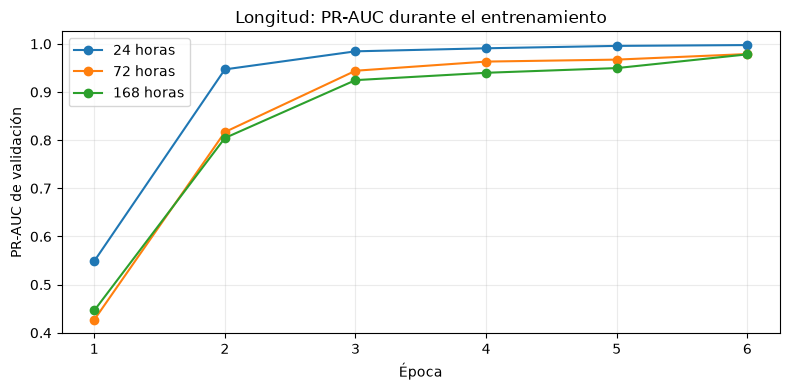

In [7]:
mejor_24 = comparacion_24h.sort_values("PR_AUC_AP", ascending=False, kind="stable").iloc[0]
seleccion_longitudes = comparacion.loc[(comparacion["arquitectura"] == mejor_24["arquitectura"])
    & (comparacion["estrategia"] == mejor_24["estrategia"])].sort_values("L")
display(seleccion_longitudes[["arquitectura", "estrategia", "L", "PR_AUC_AP", "F1_macro_5_clases", "Brier", "epocas_ejecutadas", "mejor_epoca", "segundos_totales"]].round(5))
fig, eje = plt.subplots(figsize=(8, 4))
for longitud in [24, 72, 168]:
    h = resultados[(mejor_24["arquitectura"], longitud, mejor_24["estrategia"])]["historial"]
    eje.plot(h["epoca"], h["PR_AUC_validacion"], marker="o", label=str(longitud) + " horas")
eje.set(title="Longitud: PR-AUC durante el entrenamiento", xlabel="Época", ylabel="PR-AUC de validación")
eje.legend()
eje.grid(alpha=0.25)
fig.tight_layout()
plt.show()

Para la combinación seleccionada:

- **24 horas:** PR-AUC **0.9975**, mejor época **6** de **6** ejecutadas.
- **72 horas:** PR-AUC **0.9789**, mejor época **6** de **6** ejecutadas.
- **168 horas:** PR-AUC **0.9782**, mejor época **6** de **6** ejecutadas.

Bajo este presupuesto, ampliar la ventana no mejoró el resultado de 24 horas. Las ventanas largas también aumentaron el tiempo de ajuste. No se puede concluir que más historia sea inútil en general: pueden requerirse otros parámetros, otra capacidad o más entrenamiento.

La comparación utilizó exactamente las mismas anclas, por lo que no se explica por cambiar la muestra al aumentar L. La búsqueda de longitudes se hizo solo en la combinación seleccionada y no permite generalizar a todas las arquitecturas.

## 7. Efecto de las estrategias sobre la calibración (2.3)

Una probabilidad calibrada de 0.20 significa que, entre muchas horas con predicciones cercanas a 0.20, aproximadamente 20% fueron positivas. Una buena PR-AUC solo implica buen ordenamiento, **no probabilidades calibradas**.

- **Ponderación:** aumenta la importancia de fallas durante el ajuste. Puede desplazar las probabilidades respecto a la frecuencia natural. En el caso binario ideal de entropía cruzada ponderada, se aprende una versión inclinada por los pesos del posterior; no se debe interpretar automáticamente como riesgo real.
- **Focal:** reduce la contribución de ejemplos fáciles y cambia el objetivo probabilístico. Puede modificar la confianza y no garantiza mejorar calibración, incluso si mejora PR-AUC. Aquí también usa los mismos pesos de clase, por lo que combina ambos efectos.
- **Submuestreo y sobremuestreo, no utilizados:** cambian la frecuencia de clases vista al aprender y también pueden sesgar probabilidades. Validación debe conservar su frecuencia natural.

Mediremos Brier y log loss binarios (menor es mejor), junto con ECE descriptivo en diez intervalos fijos. ECE depende de los intervalos y puede ocultar comportamiento de positivos raros; por eso se acompaña de una curva de confiabilidad y no se usa solo.

No ajustaremos calibradores ahora: la calibración formal se reserva para la tercera fase. Mostraremos las probabilidades originales, sin corregirlas mirando prueba.

,arquitectura,estrategia,PR_AUC_AP,Brier,log_loss,ECE_10_bins
4,CNN-LSTM,ponderada,0.99751,0.00073,0.00373,0.00080
5,CNN-LSTM,focal,0.99281,0.00129,0.00991,0.00743


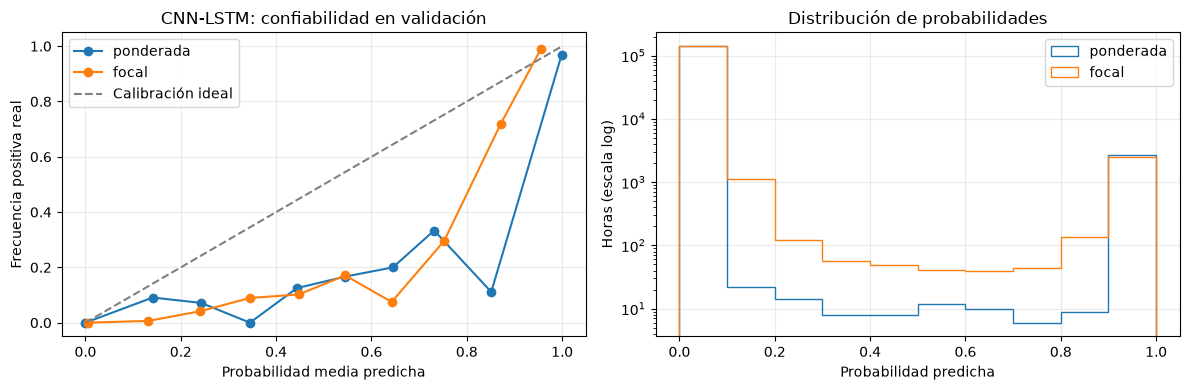

In [8]:
# Comparar calibración de ambas estrategias en la misma arquitectura y a la misma longitud.
arquitectura_calibracion = mejor_24["arquitectura"]
filas_calibracion = comparacion_24h.loc[comparacion_24h["arquitectura"] == arquitectura_calibracion]
display(filas_calibracion[["arquitectura", "estrategia", "PR_AUC_AP", "Brier", "log_loss", "ECE_10_bins"]].round(5))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for estrategia in ["ponderada", "focal"]:
    pred = resultados[(arquitectura_calibracion, 24, estrategia)]["predicciones"]
    y = pred["y_binaria"]
    p = pred["prob_binaria"]
    grupos = np.minimum((p * 10).astype(int), 9)
    puntos = []
    for grupo in range(10):
        seleccion = grupos == grupo
        if seleccion.any():
            puntos.append({"grupo": grupo, "probabilidad_media": p[seleccion].mean(),
                           "frecuencia_real": y[seleccion].mean(), "horas": int(seleccion.sum())})
    tabla = pd.DataFrame(puntos)
    ejes[0].plot(tabla["probabilidad_media"], tabla["frecuencia_real"], marker="o", label=estrategia)
    ejes[1].hist(p, bins=np.linspace(0, 1, 11), histtype="step", label=estrategia)
ejes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Calibración ideal")
ejes[0].set(title=arquitectura_calibracion + ": confiabilidad en validación", xlabel="Probabilidad media predicha", ylabel="Frecuencia positiva real")
ejes[1].set(title="Distribución de probabilidades", xlabel="Probabilidad predicha", ylabel="Horas (escala log)")
ejes[1].set_yscale("log")
for eje in ejes:
    eje.legend()
    eje.grid(alpha=0.25)
fig.tight_layout()
plt.show()

En **CNN-LSTM a 24 horas**, el Brier fue **0.00073** con ponderada y **0.00129** con focal. La log loss fue **0.00373** y **0.00991**; el ECE de diez intervalos, **0.00080** y **0.00743**, respectivamente. En estas métricas, valores menores son preferibles. La tabla y la curva permiten distinguir calibración de capacidad de ordenar fallas.

**Ejemplo para interpretar la ponderación:** si no hubiera variables informativas y equilibráramos por completo el peso de sanos y fallas, una salida constante cercana a 0.50 podría minimizar la pérdida ponderada aunque las fallas fueran aproximadamente 2% de las horas. Por eso “más peso a las fallas” no convierte sus probabilidades en riesgo real calibrado.

Focal también cambia la función que el modelo intenta minimizar; no se corrige automáticamente su probabilidad aplicando sigmoid. Sus efectos deben medirse con prevalencia natural, como aquí. No se ha reajustado ni calibrado ningún modelo después de observar estas curvas.

ECE depende de los intervalos y del predominio de horas sanas. Las regiones con pocas observaciones aportan menos y son más inciertas; esta figura no sustituye la evaluación formal de confiabilidad de la tercera fase.

## 8. Qué queda listo y qué sigue

Quedan en memoria los ocho modelos restaurados a su mejor época, los historiales y sus predicciones de validación, con el orden original de las anclas. No se seleccionó nada utilizando prueba.

Para reproducir el trabajo, se necesitan los conjuntos preparados del paso 04 y los módulos de los pasos 06 y 07. El notebook llama las funciones de `entrenamiento_secuencial.py`, que contiene pérdidas, entrenamiento, early stopping y evaluación. Sus resultados permanecen dentro del notebook: no se guardan imágenes, CSV de métricas ni modelos por separado.

En el siguiente paso se hará la comparación detallada con regresión logística y XGBoost, las métricas por componente y la anticipación con alertas sostenidas. Para reutilizar las funciones se importa el módulo; si se cierra Python, los modelos en memoria desaparecen y deberán entrenarse de nuevo. El reporte se elaborará después de revisar los resultados completos.

**Límites:** se utilizó una sola semilla y un máximo de seis épocas por ensayo. La elección de arquitectura, pérdida, longitud y época usa la misma validación, por lo que no es una evaluación final independiente. La búsqueda de longitudes no cubre todas las combinaciones. No se puede asegurar convergencia de todos los modelos al agotar el presupuesto. Las métricas son por hora, no fallas físicas evitadas ni ahorro económico.

**Qué cubre cada apartado:** el 2.3 queda documentado con las dos pérdidas y su comparación de discriminación y calibración. El 2.4 queda documentado con early stopping sobre PR-AUC, dropout, weight decay, la búsqueda por etapas de ocho ensayos y las curvas de aprendizaje. La búsqueda tiene el alcance limitado descrito arriba; no se realizó una optimización adicional de tasa de aprendizaje, tamaño de capas o regularización.

Las tablas y gráficas guardadas permiten revisar esta ejecución sin entrenar de nuevo. Si solo cambiamos títulos o explicaciones Markdown, no necesitamos repetir la celda de entrenamiento. Los objetos de los modelos, a diferencia de las salidas visibles, solo están disponibles mientras siga abierta la sesión de Python que los creó.
